In [1]:
# Cell 1 — imports and device
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
# Cell 2 — data
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset  = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

In [ ]:
# Cell 3 — sanity check BEFORE training.
xb, yb = next(iter(train_loader))
print("batch shape:", xb.shape)
print("min:", xb.min().item(), "max:", xb.max().item())   # expect 0.0 and 1.0
assert xb.min() >= 0.0 and xb.max() <= 1.0, "Targets outside [0,1] — BCE will assert"

batch shape: torch.Size([64, 1, 28, 28])
min: 0.0 max: 1.0


In [4]:
class SimpleAutoencoder(nn.Module):
    def __init__(self, bottleneck_size=2):
        super(SimpleAutoencoder, self).__init__()
        self.bottleneck_size = bottleneck_size
        
        # Encoder: 784 -> 100 -> bottleneck_size
        self.encoder = nn.Sequential(
            nn.Linear(784, 100),
            nn.ReLU(),
            nn.Linear(100, bottleneck_size)
        )
        
        # Decoder: bottleneck_size -> 100 -> 784
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_size, 100),
            nn.ReLU(),
            nn.Linear(100, 784),
            nn.Sigmoid()  # Output in [0, 1] matching our normalized inputs
        )
    
    def forward(self, x):
        x = x.view(-1, 784)           # Flatten 28x28 -> 784
        encoded = self.encoder(x)     # Shape: [batch, bottleneck_size]
        decoded = self.decoder(encoded)  # Shape: [batch, 784]
        return decoded, encoded
    
    def decode(self, z):
        """Decode from latent space back to image space"""
        decoded = self.decoder(z)
        return decoded

# Initialize model
model = SimpleAutoencoder(bottleneck_size=2).to(device)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

Model parameters: 158,186


In [5]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 10
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    num_batches = 0
    
    for batch_x, _ in train_loader:
        batch_x = batch_x.to(device)
        flat_x = batch_x.view(-1, 784)  # Flatten target too

        optimizer.zero_grad()
        reconstructed, encoded = model(batch_x)
        loss = criterion(reconstructed, flat_x)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        num_batches += 1
    
    avg_loss = running_loss / num_batches
    print(f'Epoch {epoch+1}/{num_epochs}, Average Loss: {avg_loss:.4f}')

print("Simple Autoencoder training complete!")

Epoch 1/10, Average Loss: 0.2347
Epoch 2/10, Average Loss: 0.2078
Epoch 3/10, Average Loss: 0.2012
Epoch 4/10, Average Loss: 0.1977
Epoch 5/10, Average Loss: 0.1953
Epoch 6/10, Average Loss: 0.1936
Epoch 7/10, Average Loss: 0.1921
Epoch 8/10, Average Loss: 0.1908
Epoch 9/10, Average Loss: 0.1898
Epoch 10/10, Average Loss: 0.1888
Simple Autoencoder training complete!


In [6]:
model.eval()
with torch.no_grad():
    test_images, test_labels = next(iter(test_loader))
    test_images = test_images.to(device)
    
    _, encoded_test = model(test_images)
    print(f"Encoded test data shape: {encoded_test.shape}")
    print(f"Bottleneck size: {model.bottleneck_size}")
    print(f"\nSample encoded vectors (first 5 samples):")
    print(encoded_test[:5].cpu().numpy())

Encoded test data shape: torch.Size([64, 2])
Bottleneck size: 2

Sample encoded vectors (first 5 samples):
[[-7.8900657 11.289575 ]
 [ 5.4860044  1.2009544]
 [18.567373  45.398476 ]
 [ 8.828034  -2.4060473]
 [-1.6676283  0.5952844]]


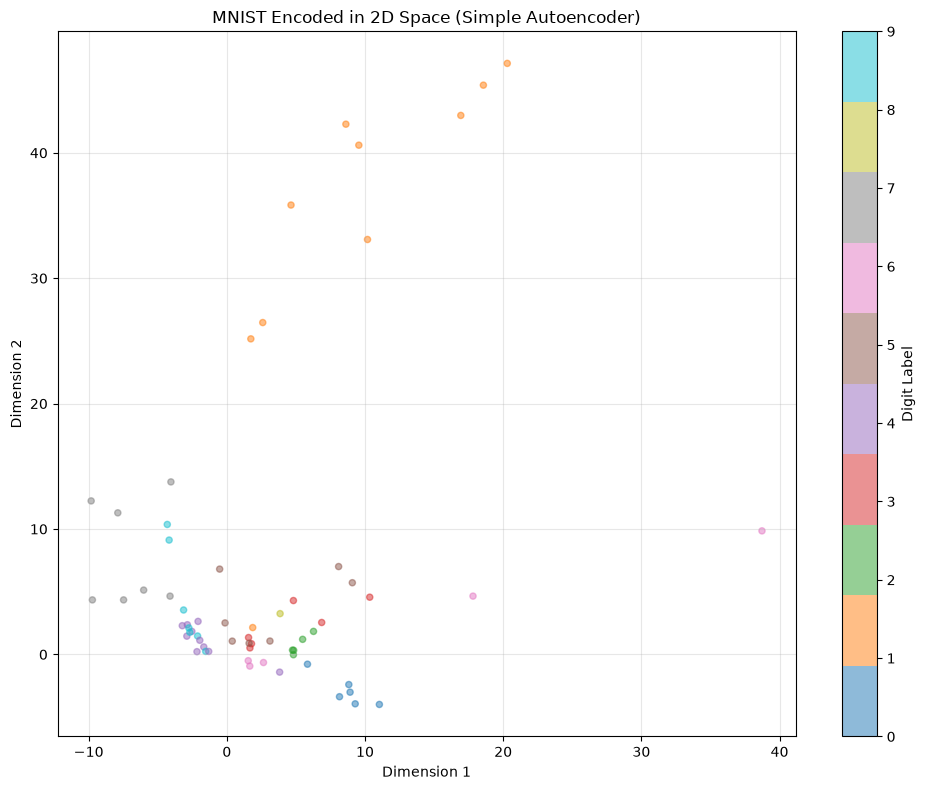

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
scatter = plt.scatter(encoded_test[:, 0].cpu(), 
                      encoded_test[:, 1].cpu(), 
                      c=test_labels.cpu(), 
                      cmap='tab10', 
                      alpha=0.5, 
                      s=20)
plt.colorbar(scatter, label='Digit Label')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.title('MNIST Encoded in 2D Space (Simple Autoencoder)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Generating from random latent vectors:


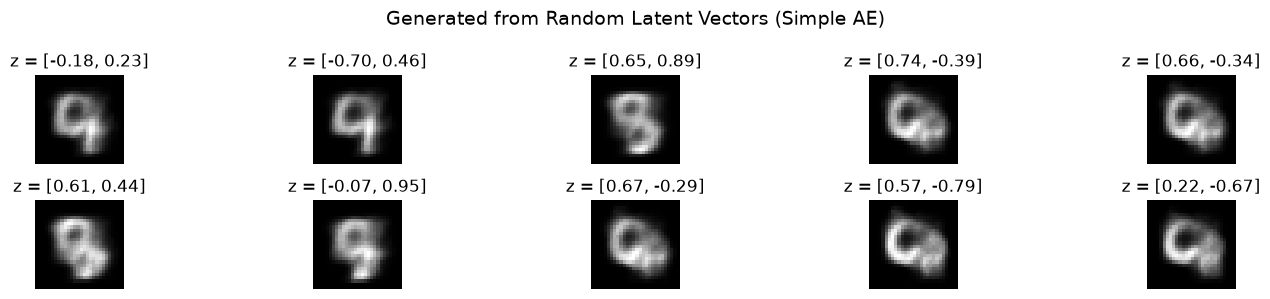

In [8]:
def generate_from_random_latent(model, num_samples=10, z_range=(-1, 1)):
    """Generate images from random latent vectors"""
    model.eval()
    with torch.no_grad():
        # Sample random values for each dimension
        random_z = torch.rand(num_samples, model.bottleneck_size).to(device)
        random_z = random_z * (z_range[1] - z_range[0]) + z_range[0]  # Scale to range
        
        generated = model.decode(random_z)
        generated = generated.reshape(num_samples, 1, 28, 28).cpu()
    
    # Display results
    fig, axes = plt.subplots(2, 5, figsize=(15, 3))
    for idx, (ax, img, z_vec) in enumerate(zip(axes.flatten(), generated, random_z)):
        ax.imshow(img[0], cmap='gray')
        ax.axis('off')
        ax.set_title(f'z = [{z_vec[0]:.2f}, {z_vec[1]:.2f}]')
    plt.suptitle('Generated from Random Latent Vectors (Simple AE)', fontsize=14)
    plt.tight_layout()
    plt.show()

print("Generating from random latent vectors:")
generate_from_random_latent(model, num_samples=10)

### Now variational Auto-Encoder

In [9]:
class VAE(nn.Module):
    def __init__(self, bottleneck_size=2):
        super(VAE, self).__init__()
        self.bottleneck_size = bottleneck_size
        
        # Encoder: 784 -> 100 -> (mu, logvar)
        self.fc1 = nn.Linear(784, 100)
        self.fc_mu = nn.Linear(100, bottleneck_size)
        self.fc_logvar = nn.Linear(100, bottleneck_size)
        
        # Decoder: bottleneck_size -> 100 -> 784
        self.dc1 = nn.Linear(bottleneck_size, 100)
        self.dc2 = nn.Linear(100, 784)
    
    def encode(self, x):
        """Returns mean and log variance"""
        h = F.relu(self.fc1(x))
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar
    
    def reparameterize(self, mu, logvar):
        """Reparameterization trick: z = μ + ε * σ"""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        """Decode from latent space"""
        h = F.relu(self.dc1(z))
        out = torch.sigmoid(self.dc2(h))
        return out
    
    def forward(self, x):
        x = x.view(-1, 784)
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z)
        return reconstructed, mu, logvar, z

vae_model = VAE(bottleneck_size=2).to(device)
print(f"VAE parameters: {sum(p.numel() for p in vae_model.parameters()):,}")

VAE parameters: 158,388


In [10]:
def vae_loss(recon_x, x, mu, logvar, beta=1.0):
    """
    VAE loss = Reconstruction loss + KL divergence
    beta controls strength of KL regularization (β-VAE)
    """
    flat_x = x.view(-1, 784)
    
    # Reconstruction loss (per element)
    recon_loss = F.binary_cross_entropy(recon_x, flat_x, reduction='sum')
    
    # KL divergence loss: -0.5 * Σ(1 + log(σ²) - μ² - σ²)
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    
    return recon_loss + beta * kl_loss

In [11]:
optimizer = optim.Adam(vae_model.parameters(), lr=0.001)

num_epochs = 20
for epoch in range(num_epochs):
    vae_model.train()
    total_loss = 0.0
    num_batches = 0
    
    for batch_x, _ in train_loader:
        batch_x = batch_x.to(device)
        
        optimizer.zero_grad()
        reconstructed, mu, logvar, z = vae_model(batch_x)
        loss = vae_loss(reconstructed, batch_x, mu, logvar)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        num_batches += 1
    
    avg_loss = total_loss / len(train_loader.dataset)
    print(f'Epoch {epoch+1}/{num_epochs}, Average Loss: {avg_loss:.4f}')

print("VAE training complete!")

Epoch 1/20, Average Loss: 195.7557
Epoch 2/20, Average Loss: 171.6319
Epoch 3/20, Average Loss: 167.1376
Epoch 4/20, Average Loss: 164.5120
Epoch 5/20, Average Loss: 162.7132
Epoch 6/20, Average Loss: 161.4077
Epoch 7/20, Average Loss: 160.3020
Epoch 8/20, Average Loss: 159.3279
Epoch 9/20, Average Loss: 158.3973
Epoch 10/20, Average Loss: 157.5498
Epoch 11/20, Average Loss: 156.7981
Epoch 12/20, Average Loss: 156.1883
Epoch 13/20, Average Loss: 155.6221
Epoch 14/20, Average Loss: 155.1430
Epoch 15/20, Average Loss: 154.6487
Epoch 16/20, Average Loss: 154.2437
Epoch 17/20, Average Loss: 153.8685
Epoch 18/20, Average Loss: 153.5700
Epoch 19/20, Average Loss: 153.2083
Epoch 20/20, Average Loss: 152.9100
VAE training complete!


In [12]:
vae_model.eval()
with torch.no_grad():
    test_images, test_labels = next(iter(test_loader))
    test_images = test_images.to(device)
    
    _, mu_vae, logvar_vae, z_vae = vae_model(test_images)
    
    print(f"VAE Mu (mean) shape: {mu_vae.shape}")
    print(f"VAE LogVar shape: {logvar_vae.shape}")
    print(f"Z sampled shape: {z_vae.shape}")
    print(f"\nSample mu values (first 5):")
    print(mu_vae[:5].cpu().numpy())
    print(f"\nSample z values (first 5):")
    print(z_vae[:5].cpu().numpy())

VAE Mu (mean) shape: torch.Size([64, 2])
VAE LogVar shape: torch.Size([64, 2])
Z sampled shape: torch.Size([64, 2])

Sample mu values (first 5):
[[-2.3218923   1.0903139 ]
 [ 0.10997877 -0.44542652]
 [ 0.51409125  3.7039454 ]
 [ 0.82637674 -1.5873833 ]
 [-1.4594413  -0.34164318]]

Sample z values (first 5):
[[-2.4828432   1.1906672 ]
 [ 0.08160704 -0.4852482 ]
 [ 0.37422097  3.4409683 ]
 [ 0.80156446 -1.3400096 ]
 [-1.348163   -0.36555812]]


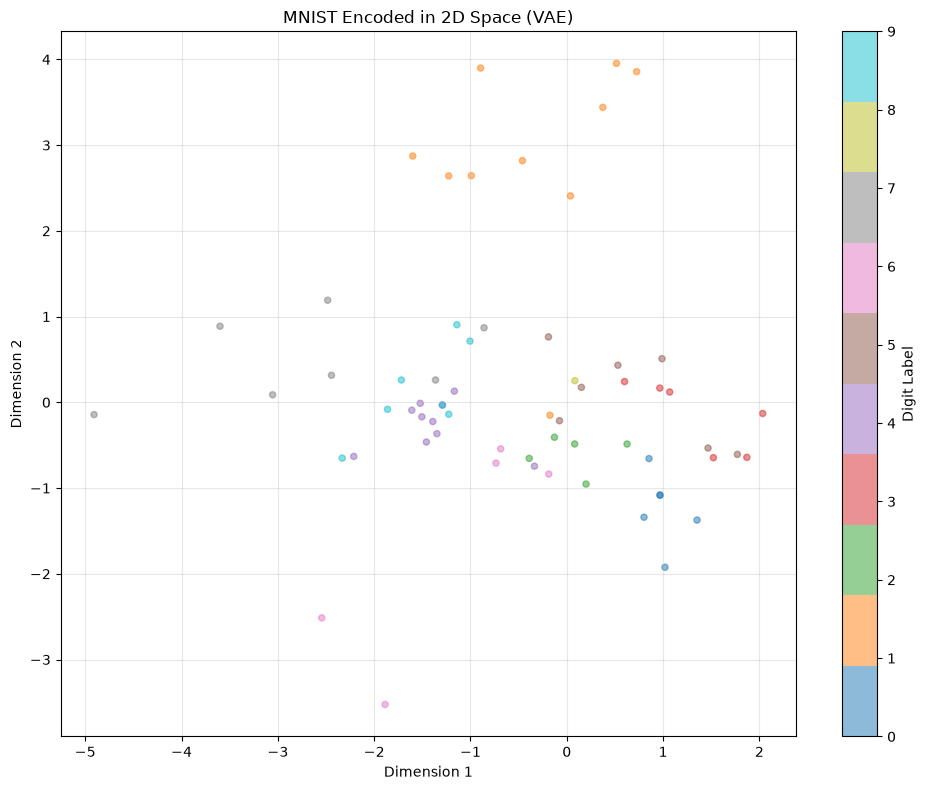

In [13]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(z_vae[:, 0].cpu(), 
                      z_vae[:, 1].cpu(), 
                      c=test_labels.cpu(), 
                      cmap='tab10', 
                      alpha=0.5, 
                      s=20)
plt.colorbar(scatter, label='Digit Label')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.title('MNIST Encoded in 2D Space (VAE)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Generating from manual z values:


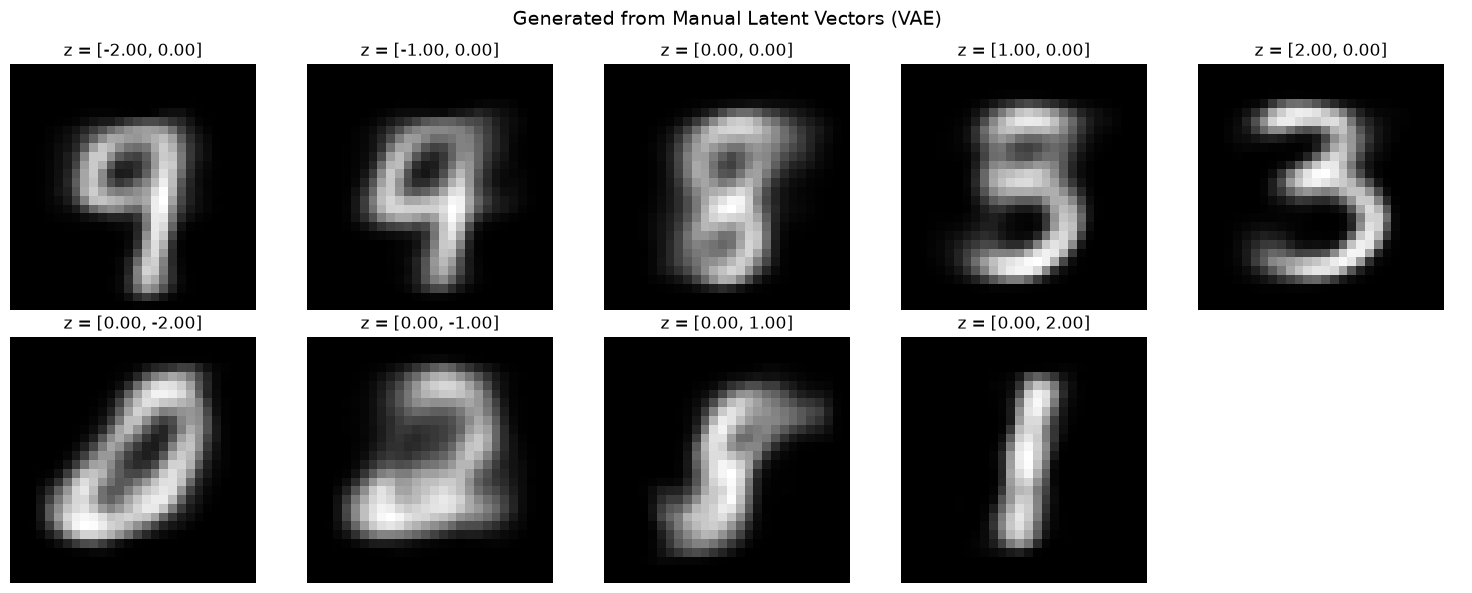

In [14]:
def generate_from_vae_manual(model, z_values):
    """Generate from manually specified latent vectors"""
    model.eval()
    z_tensor = torch.FloatTensor(z_values).to(device)
    
    with torch.no_grad():
        generated = model.decode(z_tensor)
        generated = generated.reshape(len(z_values), 1, 28, 28).cpu()
    
    # Determine grid size
    n = len(z_values)
    cols = min(5, n)
    rows = (n + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3 * rows))
    if rows == 1:
        axes = axes.reshape(1, -1)
    
    for idx, (ax, img, z_vec) in enumerate(zip(axes.flatten(), generated, z_values)):
        ax.imshow(img[0], cmap='gray')
        ax.axis('off')
        ax.set_title(f'z = [{z_vec[0]:.2f}, {z_vec[1]:.2f}]')
    
    # Hide unused subplots
    for idx in range(n, rows * cols):
        axes.flatten()[idx].axis('off')
    
    plt.suptitle('Generated from Manual Latent Vectors (VAE)', fontsize=14)
    plt.tight_layout()
    plt.show()

# Try some hand-picked values (experiment with different ranges!)
print("\nGenerating from manual z values:")
manual_z = [
    [-2, 0], [-1, 0], [0, 0], [1, 0], [2, 0],  # Horizontal line
    [0, -2], [0, -1], [0, 0], [0, 1], [0, 2]   # Vertical line (reuse center)
]
# Remove duplicate center
manual_z = [[-2, 0], [-1, 0], [0, 0], [1, 0], [2, 0], [0, -2], [0, -1], [0, 1], [0, 2]]
generate_from_vae_manual(vae_model, manual_z)

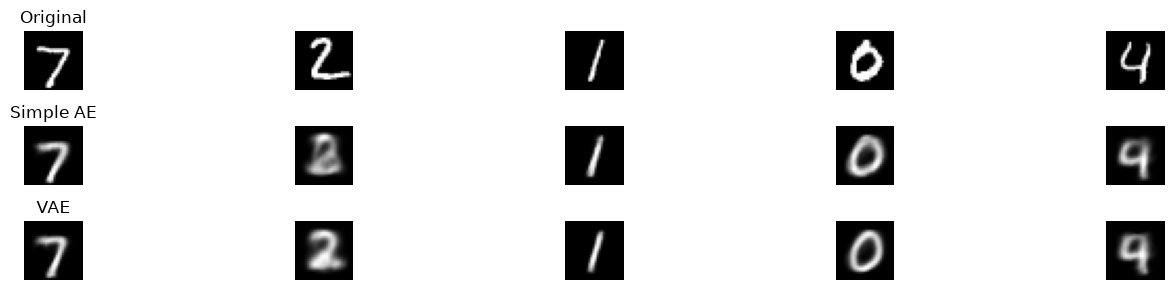

In [15]:
model.eval()
vae_model.eval()

with torch.no_grad():
    test_batch, _ = next(iter(test_loader))
    test_batch = test_batch.to(device)
    
    # Simple AE reconstruction
    _, _ = model(test_batch)
    reconstructed_simple, _ = model(test_batch)
    
    # VAE reconstruction  
    _, _, _, _ = vae_model(test_batch)
    reconstructed_vae, _, _, _ = vae_model(test_batch)
    
    # Display comparison
    fig, axes = plt.subplots(3, 5, figsize=(15, 3))
    
    for i in range(5):
        # Original
        axes[0, i].imshow(test_batch[i].cpu().reshape(28, 28), cmap='gray')
        axes[0, i].axis('off')
        if i == 0:
            axes[0, i].set_title('Original')
        
        # Simple AE
        axes[1, i].imshow(reconstructed_simple[i].cpu().reshape(28, 28), cmap='gray')
        axes[1, i].axis('off')
        if i == 0:
            axes[1, i].set_title('Simple AE')
        
        # VAE
        axes[2, i].imshow(reconstructed_vae[i].cpu().reshape(28, 28), cmap='gray')
        axes[2, i].axis('off')
        if i == 0:
            axes[2, i].set_title('VAE')

plt.tight_layout()
plt.show()